# Кластеризация ЕГЭ (8.5 если сделаны все задачи)


Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000


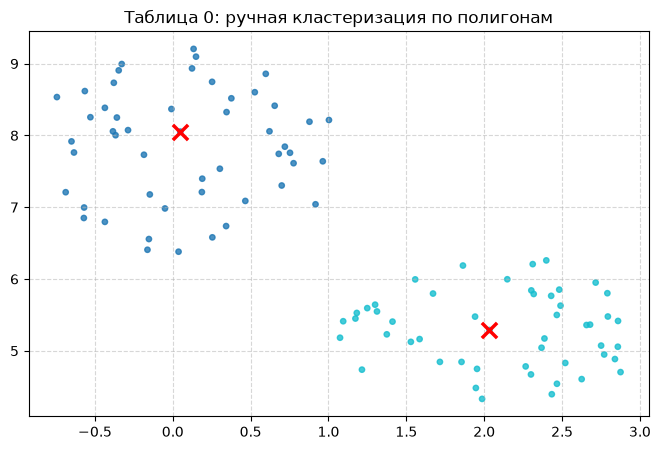

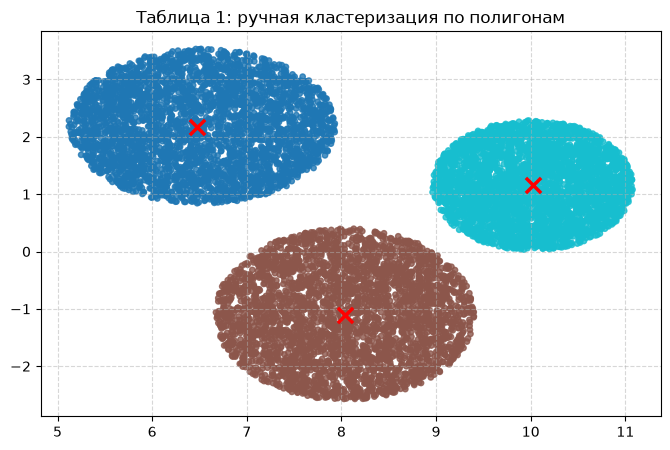

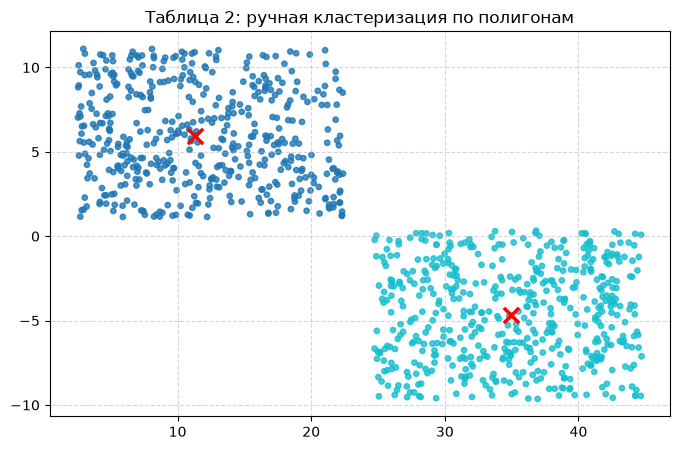

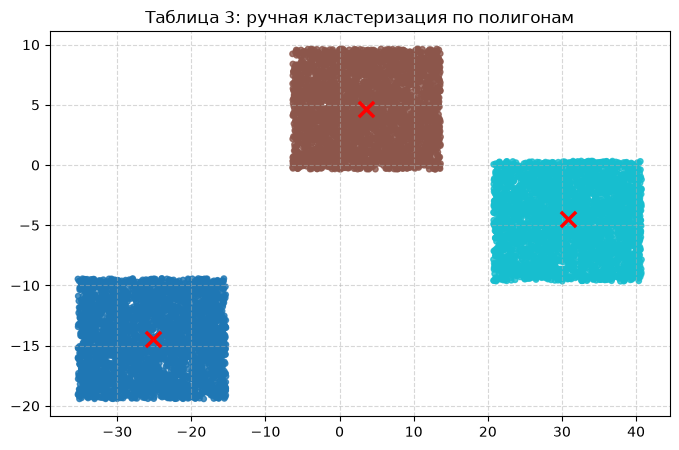

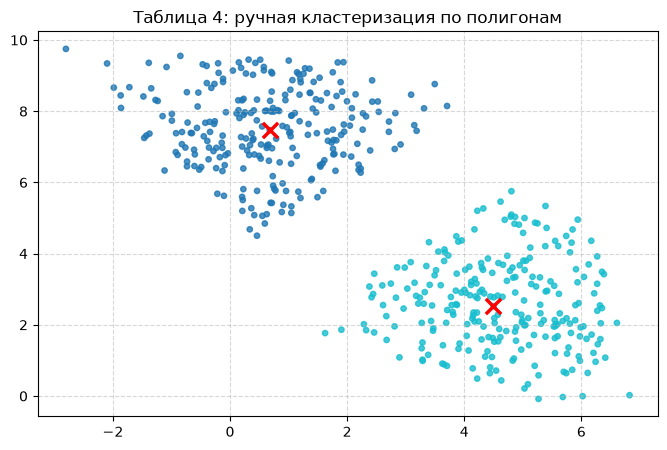

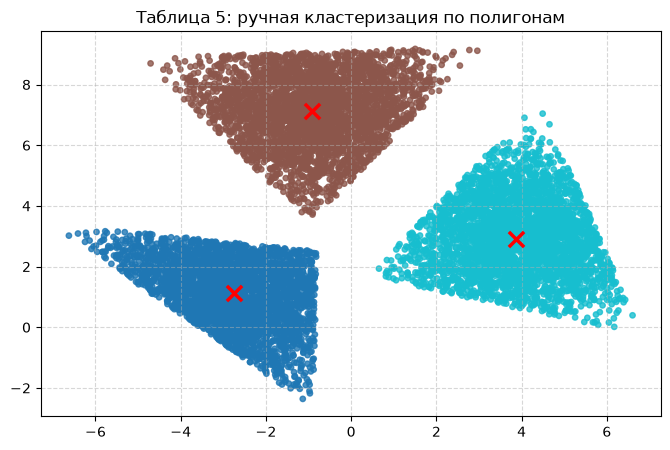

,Таблица,Кластер,X медоида,Y медоида,Количество точек
0,Таблица 0,1,0.048112,8.053051,50
1,Таблица 0,2,2.033901,5.289296,50
2,Таблица 1,1,6.469983,2.169761,3333
3,Таблица 1,2,8.040075,-1.108706,3333
4,Таблица 1,3,10.022535,1.154201,3333
5,Таблица 2,1,11.334080,5.965961,476
6,Таблица 2,2,34.926351,-4.695276,524
7,Таблица 3,1,-25.130758,-14.413328,3429
8,Таблица 3,2,3.517911,4.653696,3284
9,Таблица 3,3,30.849529,-4.517203,3287


In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path as PolygonPath
from sklearn.metrics import pairwise_distances

base_dir = '/Users/darm_s/Downloads/EGE/'

file_mapping = {
    "Таблица 0": ('0.xls', 0),
    "Таблица 1": ('1.xls', 0),
    "Таблица 2": ('2.xlsx', None),
    "Таблица 3": ('3.xlsx', None),
    "Таблица 4": ('4.xlsx', 0),
    "Таблица 5": ('5.xlsx', 0),
}

data_tables = {}
for title, (filename, header) in file_mapping.items():
    path = os.path.join(base_dir, filename) if os.path.exists(os.path.join(base_dir, filename)) else filename
    df = pd.read_excel(path, header=header)
    df.columns = ['X', 'Y']
    data_tables[title] = df[['X', 'Y']].values

manual_polygons = {
    "Таблица 0": [
        [[-3, 3], [-3, 12], [1.04, 12], [1.04, 3]],
        [[1.04, 3], [1.04, 12], [5, 12], [5, 3]],
    ],
    "Таблица 1": [
        [[3, 0.6], [3, 5], [8.6, 5], [8.6, 0.6]],
        [[3, 0.6], [8.6, 0.6], [9.0, 0.4], [9.5, -0.3], [9.8, -0.6], [12, -0.6], [12, -5], [3, -5]],
        [[8.6, 0.6], [8.6, 5], [12, 5], [12, -0.6], [9.8, -0.6], [9.5, -0.3], [9.0, 0.4]],
    ],
    "Таблица 2": [
        [[0, -15], [0, 15], [23.5, 15], [23.5, -15]],
        [[23.5, -15], [23.5, 15], [50, 15], [50, -15]],
    ],
    "Таблица 3": [
        [[-45, -30], [-45, 15], [-10, 15], [-10, -30]],
        [[-10, -30], [-10, 15], [17, 15], [17, -30]],
        [[17, -30], [17, 15], [50, 15], [50, -30]],
    ],
    "Таблица 4": [
        [[-5, 4.495], [-5, 12], [3.9, 12], [3.9, 4.495]],
        [[-5, -3], [-5, 4.495], [3.9, 4.495], [3.9, 12], [9, 12], [9, -3]],
    ],
    "Таблица 5": [
        [[-9, 3.5], [-9, -4], [0.0, -4], [0.0, 3.5]],
        [[-9, 3.5], [0.0, 3.5], [1.5, 3.5], [6, 9.5], [6, 12], [-9, 12]],
        [[0.0, -4], [0.0, 3.5], [1.5, 3.5], [6, 9.5], [10, 9.5], [10, -4]],
    ],
}

metrics = {
    "Таблица 0": "euclidean",
    "Таблица 1": "euclidean",
    "Таблица 2": "euclidean",
    "Таблица 3": "manhattan",
    "Таблица 4": "manhattan",
    "Таблица 5": "euclidean",
}

medoid_rows = []

for title, points in data_tables.items():
    distances = pairwise_distances(points, metric=metrics[title])

    fig, ax = plt.subplots(figsize=(8, 5))
    
    cluster_labels = np.full(len(points), -1)

    for number, vertices in enumerate(manual_polygons[title], start=1):
        indices = np.where(PolygonPath(vertices).contains_points(points))[0]
        cluster_labels[indices] = number - 1  # присваиваем номер кластера для цвета

        if len(indices) > 0:
            sums = distances[np.ix_(indices, indices)].sum(axis=1)
            medoid_index = indices[np.argmin(sums)]

            medoid_rows.append({
                "Таблица": title,
                "Кластер": number,
                "X медоида": points[medoid_index, 0],
                "Y медоида": points[medoid_index, 1],
                "Количество точек": len(indices),
            })
            
            ax.scatter(points[medoid_index, 0], points[medoid_index, 1], color='red', marker='x', s=120, linewidths=2.5, zorder=5)

    scatter = ax.scatter(points[:, 0], points[:, 1], c=cluster_labels, cmap='tab10', s=15, alpha=0.8)

    ax.set_title(title + ": ручная кластеризация по полигонам")
    ax.grid(True, linestyle='--', alpha=0.5)
    plt.show()

medoids = pd.DataFrame(medoid_rows)
try:
    display(medoids)
except NameError:
    print(medoids)

# Кластеризация (0.75 за каждый алгоритм на всех данных)


На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)


In [25]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
from itertools import cycle, islice


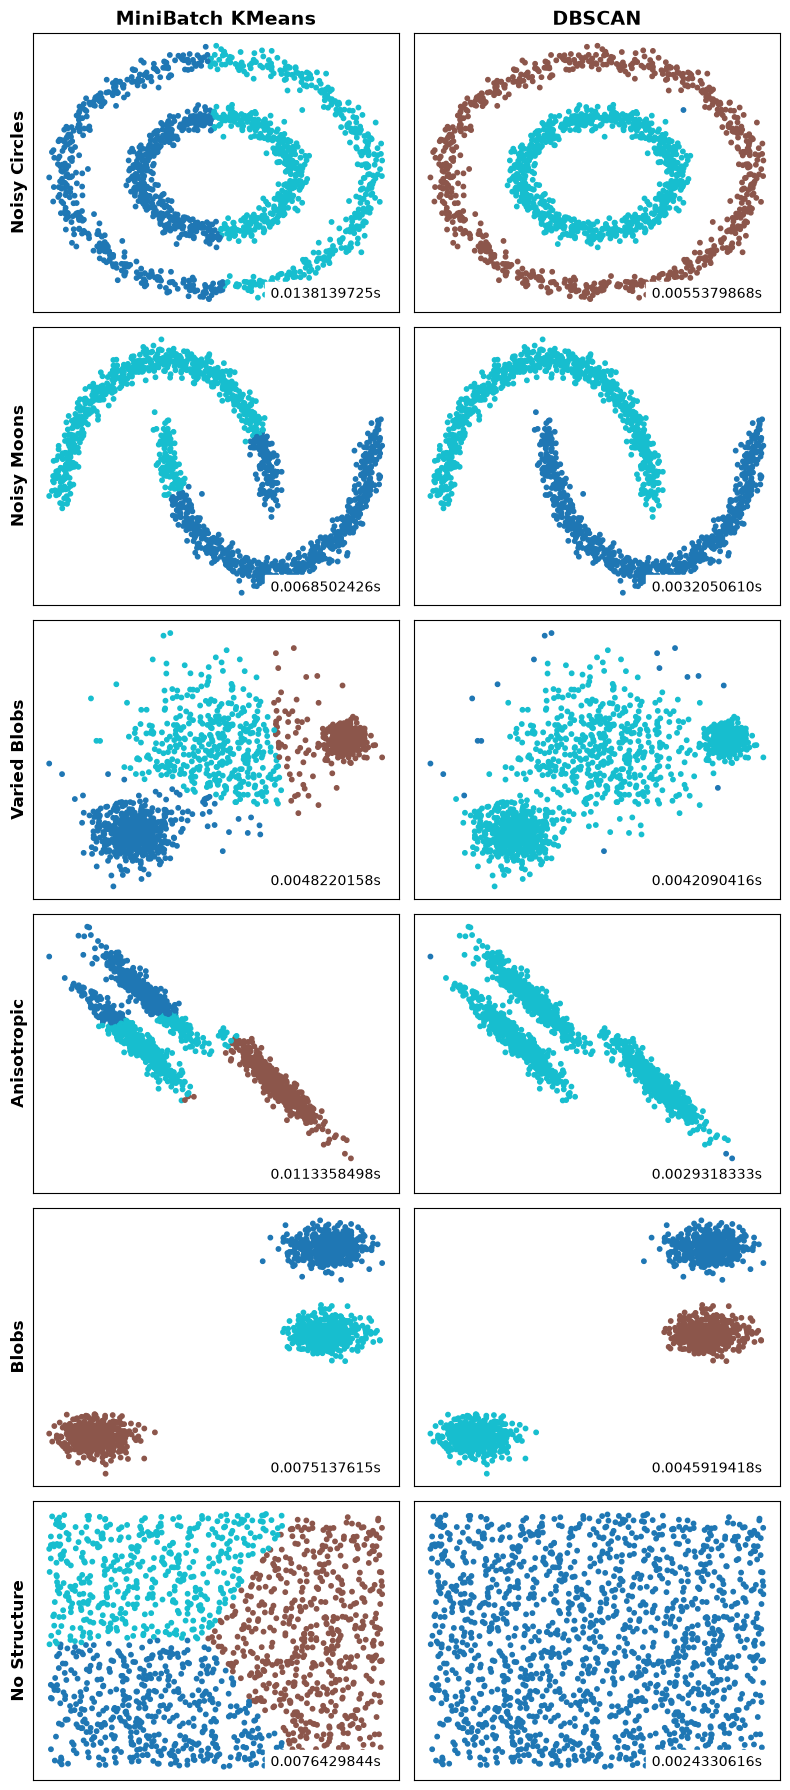

In [26]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn import cluster, datasets
from sklearn.preprocessing import StandardScaler

np.random.seed(0)
n_samples = 1500

datasets_list = [
    ("Noisy Circles", datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)),
    ("Noisy Moons", datasets.make_moons(n_samples=n_samples, noise=0.05)),
    ("Varied Blobs", datasets.make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=170)),
    ("Anisotropic", (np.dot(datasets.make_blobs(n_samples=n_samples, random_state=170)[0], [[0.6, -0.6], [-0.4, 0.8]]), None)),
    ("Blobs", datasets.make_blobs(n_samples=n_samples, random_state=8)),
    ("No Structure", (np.random.rand(n_samples, 2), None)),
]

fig, axes = plt.subplots(len(datasets_list), 2, figsize=(8, 18))

for row_idx, (name, (X, y)) in enumerate(datasets_list):
    X = StandardScaler().fit_transform(X)

    algorithms = [
        ("MiniBatch KMeans", cluster.MiniBatchKMeans(n_clusters=2 if "Circles" in name or "Moons" in name else 3, n_init="auto")),
        ("DBSCAN", cluster.DBSCAN(eps=0.2 if "Circles" in name or "Moons" in name else 0.3))
    ]

    for col_idx, (algo_name, algo) in enumerate(algorithms):
        ax = axes[row_idx, col_idx]

        t0 = time.time()
        y_pred = algo.fit_predict(X)
        t1 = time.time()

        ax.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='tab10', s=10)
        ax.set_xticks(())
        ax.set_yticks(())

        if row_idx == 0:
            ax.set_title(algo_name, fontsize=14, fontweight='bold')
            
        if col_idx == 0:
            ax.set_ylabel(name, fontsize=12, fontweight='bold')

        ax.text(0.95, 0.05, f"{t1 - t0:.10f}s", transform=ax.transAxes, 
                ha='right', fontsize=10, backgroundcolor='white')

plt.tight_layout()
plt.show()